# Invoice Anomaly — EDA acadêmica exclusivamente no TRAIN

Esta análise descreve o **artefato processado de TRAIN**, não reabre a avaliação do modelo. O objetivo atual do Invoice é triagem de anomalias para auditoria humana, não classificação automática de fraude. O Isolation Forest é não supervisionado: `is_fraud` é apenas referência exploratória, nunca feature de treinamento.

**Fonte única:** `data/processed/train_features.parquet`. Não há leitura de VALIDATION, TEST, raw compartilhados, modelos ou resultados de avaliação. Nenhum fit, inferência, transformação adicional, remoção de outliers ou decisão de modelagem é realizado.

## Escopo e limite dos dois níveis de EDA

1. **Estrutura disponível:** o TRAIN processado contém somente as 19 features, `invoice_id`, `split`, `is_fraud` e `fraud_type`. A visão geral abaixo limita-se a essas 23 colunas; não é uma inspeção completa do dataset original.
2. **Features do modelo:** estatísticas, distribuições, comparação descritiva por label e correlações das 19 variáveis existentes.

Identificadores originais de fornecedor e departamento, país, datas, horas originais e demais atributos brutos não estão presentes. Não é possível contar fornecedores/departamentos/países, descrever suas categorias ou determinar período sem consultar raw compartilhados. **Esses arquivos não serão abertos**; frequências agregadas e componentes cíclicos não serão usados para reconstruir campos ausentes.

## Reprodução

Executar todas as células em um kernel do ambiente do projeto com Pandas, NumPy, Matplotlib e IPython. As dependências opcionais de notebooks já adotadas pelo projeto incluem Matplotlib 3.10.8, nbformat 5.10.4, nbclient 0.10.4 e ipykernel 7.2.0. Nenhuma nova dependência de produção é necessária. A raiz é localizada a partir da pasta atual, sem caminhos pessoais.


In [2]:
import hashlib
import io
import platform
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    candidate for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "ml/scripts/treinar_modelo.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Importação segura: main() não é chamada. Não importar preparar_features.
from ml.scripts.treinar_modelo import FEATURES

assert len(FEATURES) == 19
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

environment = {"Python": platform.python_version()}
environment.update({name: version(name) for name in
                    ["pandas", "numpy", "pyarrow", "matplotlib", "scikit-learn"]})
display(pd.Series(environment, name="versão"))


Python          3.14.3
pandas           2.3.3
numpy            2.5.2
pyarrow         25.0.1
matplotlib      3.10.8
scikit-learn     1.9.0
Name: versão, dtype: object

## Funções de leitura e estatística

O carregador usa um único caminho fixo de TRAIN, rejeita redirecionamentos de caminho, lê seus bytes uma vez e calcula o SHA-256 desses mesmos bytes. Não busca outro split como fallback. O schema, ordem das features, IDs, split e referência binária são verificados antes da análise.

As funções abaixo apenas resumem dados existentes; não reproduzem engenharia de features. Nulos numéricos são preservados e contabilizados (estatísticas usam observações presentes); infinitos impedem a análise. Correlação indefinida permanece NaN, nunca é substituída por zero.


In [3]:
def load_train(project_root):
    root = Path(project_root).resolve()
    path = root / "data/processed/train_features.parquet"
    if path.resolve() != path:
        raise ValueError("Caminho TRAIN redirecionado; leitura bloqueada.")
    payload = path.read_bytes()
    frame = pd.read_parquet(io.BytesIO(payload))
    expected = {"invoice_id", "split", "is_fraud", "fraud_type", *FEATURES}
    if frame.empty or not frame.columns.is_unique or set(frame.columns) != expected:
        raise ValueError("Schema TRAIN vazio ou incompatível com as 23 colunas.")
    if [name for name in frame.columns if name in FEATURES] != FEATURES:
        raise ValueError("Ordem das 19 features incompatível.")
    if frame["split"].isna().any() or not frame["split"].eq("train").all():
        raise ValueError("Somente linhas TRAIN são permitidas.")
    ids = frame["invoice_id"]
    if ids.isna().any() or ids.duplicated().any() or not ids.map(
        lambda value: isinstance(value, str) and bool(value.strip())
    ).all():
        raise ValueError("invoice_id inválido, nulo ou duplicado.")
    target = frame["is_fraud"]
    if (not pd.api.types.is_integer_dtype(target)
            or target.isna().any() or not target.isin([0, 1]).all()):
        raise ValueError("is_fraud deve ser inteiro binário 0/1 sem nulos.")
    if not frame["fraud_type"].dropna().map(lambda value: isinstance(value, str)).all():
        raise ValueError("fraud_type deve conter texto ou nulo.")
    for name in FEATURES:
        values = frame[name]
        if (not pd.api.types.is_numeric_dtype(values)
                or pd.api.types.is_bool_dtype(values)
                or pd.api.types.is_complex_dtype(values)
                or np.isinf(values.to_numpy(dtype=float, na_value=np.nan)).any()):
            raise ValueError(f"Feature numérica inválida: {name}")
    return frame, hashlib.sha256(payload).hexdigest()


def describe_numeric(frame):
    summary = frame.describe().T.rename(columns={"25%": "Q1", "50%": "median", "75%": "Q3"})
    summary["null_count"] = frame.isna().sum()
    summary["null_percent"] = 100 * frame.isna().mean()
    summary["zero_count"] = frame.eq(0).sum()
    return summary[["count", "mean", "median", "std", "min", "Q1", "Q3", "max",
                    "null_count", "null_percent", "zero_count"]]


def target_correlations(features, target):
    if not features.index.equals(target.index):
        raise ValueError("Features e referência devem estar alinhadas.")
    varying = features.loc[:, features.nunique() > 1]
    result = pd.DataFrame(index=features.columns, columns=["pearson", "spearman"], dtype=float)
    if target.nunique() > 1:
        for method in result.columns:
            result.loc[varying.columns, method] = varying.corrwith(target, method=method)
    return result.sort_values("pearson", key=lambda column: column.abs(),
                              ascending=False, na_position="last", kind="stable")


def correlation_pairs(matrix):
    records = [
        {"feature_a": a, "feature_b": b, "correlation": matrix.loc[a, b]}
        for i, a in enumerate(matrix.columns)
        for b in matrix.columns[i + 1:]
    ]
    return pd.DataFrame(records).sort_values(
        "correlation", key=lambda column: column.abs(), ascending=False, kind="stable"
    ).reset_index(drop=True)


def compare_classes(features, target):
    if not features.index.equals(target.index):
        raise ValueError("Features e referência devem estar alinhadas.")
    return features.groupby(target).agg(["count", "mean", "median", "std"])


## 1. Leitura exclusiva e visão geral


In [4]:
dados_train, train_sha256 = load_train(PROJECT_ROOT)
assert len(dados_train) == 210_000, (
    "Revisar escopo: número de registros diferente do TRAIN aprovado."
)
features_train = dados_train.loc[:, FEATURES].copy()
referencia_fraude = dados_train["is_fraud"].copy()
print("Fonte: data/processed/train_features.parquet")
print("SHA-256:", train_sha256)
print(
    f"Registros: {len(dados_train):,}; colunas: {dados_train.shape[1]}; features: {features_train.shape[1]}"
)
print("Duplicatas exatas (23 colunas):", int(dados_train.duplicated().sum()))
print("IDs duplicados:", int(dados_train["invoice_id"].duplicated().sum()))
print(
    "Vetores repetidos de features (não implicam duplicata de fatura):",
    int(features_train.duplicated().sum()),
)
schema = pd.DataFrame(
    {
        "dtype": dados_train.dtypes.astype(str),
        "presentes": dados_train.notna().sum(),
        "nulos": dados_train.isna().sum(),
        "nulos_percent": 100 * dados_train.isna().mean(),
        "valores_unicos": dados_train.nunique(dropna=True),
    }
)
display(schema)
print(
    "Infinitos nas features:",
    int(np.isinf(features_train.to_numpy(dtype=float, na_value=np.nan)).sum()),
)
print("Colunas usadas como features:", list(features_train.columns))


Fonte: data/processed/train_features.parquet
SHA-256: 41cfbb25baa62c1c201ce5bbc310589fd41656efae9c1d51684716cea0d6e72b
Registros: 210,000; colunas: 23; features: 19
Duplicatas exatas (23 colunas): 0
IDs duplicados: 0


Vetores repetidos de features (não implicam duplicata de fatura): 0


,dtype,presentes,nulos,nulos_percent,valores_unicos
invoice_id,object,210000,0,0.000000,210000
split,object,210000,0,0.000000,1
is_fraud,int64,210000,0,0.000000,2
fraud_type,object,210000,0,0.000000,6
invoice_amount,float64,210000,0,0.000000,194188
log_invoice_amount,float64,210000,0,0.000000,194188
supplier_age_days,int64,210000,0,0.000000,1564
supplier_frequency,float64,210000,0,0.000000,64
country_frequency,float64,210000,0,0.000000,123
amount_vs_supplier_mean,float64,210000,0,0.000000,209981


Infinitos nas features: 0
Colunas usadas como features: ['invoice_amount', 'log_invoice_amount', 'supplier_age_days', 'supplier_frequency', 'country_frequency', 'amount_vs_supplier_mean', 'supplier_amount_zscore', 'department_frequency', 'amount_vs_department_mean', 'supplier_department_frequency', 'payment_terms_days', 'invoice_type_encoded', 'submission_hour_sin', 'submission_hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_weekend']


## 2. Referência `is_fraud` e colunas categóricas disponíveis

Os nomes “0” e “1” referem-se à label do dataset, não à comprovação de normalidade ou fraude empresarial. `fraud_type` também é referência, não feature. O identificador é usado somente para integridade; não se calcula sua correlação.


,quantidade,percentual
is_fraud,,
0,163873,78.034762
1,46127,21.965238


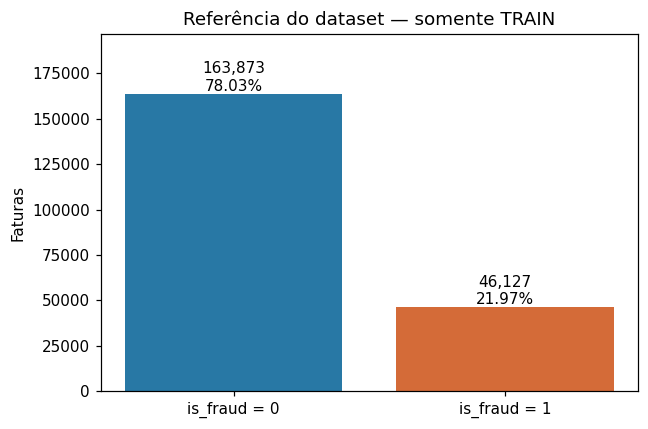

split: 1 categorias não nulas


,quantidade,percentual
split,,
train,210000,100.000000


fraud_type: 6 categorias não nulas


,quantidade,percentual
fraud_type,,
NONE,166360,79.219048
SPLIT,29261,13.933810
GHOST_SUPPLIER,8795,4.188095
INFLATED,3884,1.849524
DOC_TAMPER,1650,0.785714
DUPLICATE,50,0.023810


fraud_type,DOC_TAMPER,DUPLICATE,GHOST_SUPPLIER,INFLATED,NONE,SPLIT
is_fraud,,,,,,
0,38,0,164,81,162986,604
1,1612,50,8631,3803,3374,28657


In [5]:
contagem_classes = (
    referencia_fraude.value_counts().reindex([0, 1], fill_value=0).rename("quantidade")
)
distribuicao_classes = contagem_classes.to_frame()
distribuicao_classes["percentual"] = 100 * contagem_classes / len(dados_train)
display(distribuicao_classes)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["is_fraud = 0", "is_fraud = 1"], contagem_classes, color=["#2878a5", "#d46b38"])
for i, count in enumerate(contagem_classes):
    ax.text(
        i,
        count,
        f"{count:,}\n{100 * count / len(dados_train):.2f}%",
        ha="center",
        va="bottom",
    )
ax.set(
    ylabel="Faturas",
    title="Referência do dataset — somente TRAIN",
    ylim=(0, contagem_classes.max() * 1.2),
)
plt.tight_layout()
plt.show()

for name in ["split", "fraud_type"]:
    counts = dados_train[name].value_counts(dropna=False)
    print(f"{name}: {dados_train[name].nunique(dropna=True)} categorias não nulas")
    display(
        pd.DataFrame(
            {"quantidade": counts, "percentual": 100 * counts / len(dados_train)}
        )
    )
display(pd.crosstab(referencia_fraude, dados_train["fraud_type"], dropna=False))


## 3. Estatísticas das 19 features existentes

Desvio padrão amostral (`ddof=1`), quartis e contagem de zeros são descritivos. Zero não é tratado automaticamente como ausência ou erro. Nas variáveis binárias/cíclicas/codificadas, zero tem interpretação dependente da representação, não de magnitude econômica.

Não há imputação, scaling, encoding adicional nem reconstrução de variáveis.


In [6]:
estatisticas_features = describe_numeric(features_train)
display(estatisticas_features)
resumo_distribuicoes = pd.DataFrame(
    {
        "assimetria_amostral": features_train.skew(),
        "valores_unicos": features_train.nunique(),
        "frequencia_valor_mais_comum_percent": [
            100 * features_train[name].value_counts(normalize=True).max()
            for name in FEATURES
        ],
    }
)
display(resumo_distribuicoes)


,count,mean,median,std,min,Q1,Q3,max,null_count,null_percent,zero_count
invoice_amount,210000.000000,7566.227651,4898.555000,8793.285807,70.000000,2640.852500,9178.672500,294048.720000,0,0.000000,0
log_invoice_amount,210000.000000,8.502220,8.496900,0.925401,4.262680,7.879236,9.124747,12.591504,0,0.000000,0
supplier_age_days,210000.000000,2258.827267,2236.000000,1567.741606,30.000000,800.000000,3629.000000,4999.000000,0,0.000000,0
supplier_frequency,210000.000000,0.000505,0.000505,0.000049,0.000338,0.000471,0.000538,0.000667,0,0.000000,0
country_frequency,210000.000000,0.010697,0.010448,0.005035,0.000548,0.005900,0.015119,0.020548,0,0.000000,0
amount_vs_supplier_mean,210000.000000,1.000000,0.836947,0.652884,0.037346,0.559543,1.253897,10.515928,0,0.000000,0
supplier_amount_zscore,210000.000000,0.000000,-0.251137,0.995229,-1.821241,-0.674686,0.395521,9.106173,0,0.000000,0
department_frequency,210000.000000,0.020003,0.020014,0.000265,0.019481,0.019771,0.020162,0.020510,0,0.000000,0
amount_vs_department_mean,210000.000000,1.000000,0.647261,1.161523,0.009232,0.349063,1.213040,39.374389,0,0.000000,0
supplier_department_frequency,210000.000000,0.000015,0.000014,0.000007,0.000005,0.000010,0.000019,0.000052,0,0.000000,0


,assimetria_amostral,valores_unicos,frequencia_valor_mais_comum_percent
invoice_amount,4.716840,194188,0.002381
log_invoice_amount,0.010771,194188,0.002381
supplier_age_days,0.081157,1564,0.301429
supplier_frequency,0.057077,64,4.169048
country_frequency,0.162601,123,2.054762
amount_vs_supplier_mean,2.220211,209981,0.000952
supplier_amount_zscore,1.870766,209981,0.000952
department_frequency,0.152145,48,3.992381
amount_vs_department_mean,4.707966,209649,0.000952
supplier_department_frequency,0.690500,11,27.070000


## 4. Distribuições e outliers — histogramas e boxplots

Cada feature recebe histograma e boxplot, sem recorte de valores ou transformação. Escalas muito amplas podem comprimir a região central; isso é mostrado, não corrigido.

**Outlier estatístico não deve ser tratado automaticamente como erro de dados.** As cercas Q1 − 1,5×IQR e Q3 + 1,5×IQR são apenas descritores. Em variáveis discretas, binárias, codificadas ou cíclicas, essa regra pode marcar valores legítimos e não significa alerta de fraude. Pontos no boxplot não são scores do Isolation Forest.


,limite_inferior_IQR,limite_superior_IQR,fora_cercas_IQR,percentual
invoice_amount,-7165.877500,18985.402500,15382,7.324762
log_invoice_amount,6.010969,10.993014,1531,0.729048
supplier_age_days,-3443.500000,7872.500000,0,0.000000
supplier_frequency,0.000371,0.000638,1202,0.572381
country_frequency,-0.007929,0.028948,0,0.000000
amount_vs_supplier_mean,-0.481987,2.295428,9524,4.535238
supplier_amount_zscore,-2.279996,2.000830,9865,4.697619
department_frequency,0.019186,0.020748,0,0.000000
amount_vs_department_mean,-0.946902,2.509006,15377,7.322381
supplier_department_frequency,-0.000005,0.000033,1279,0.609048


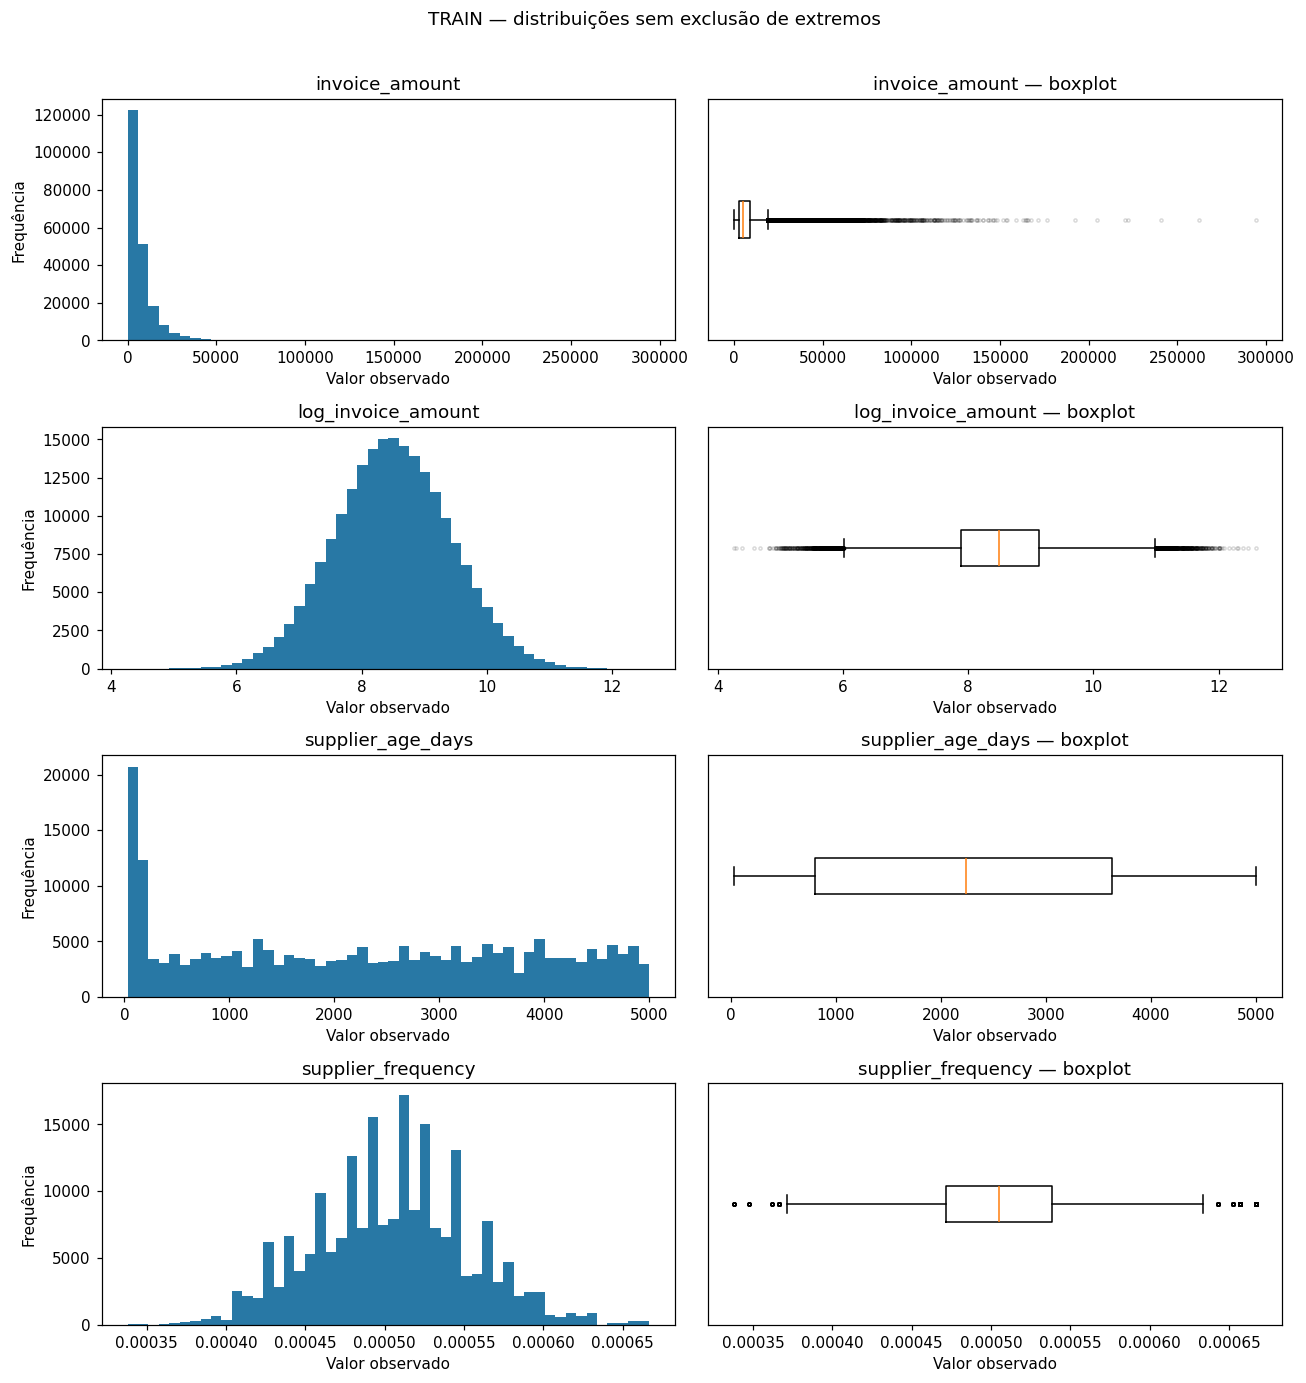

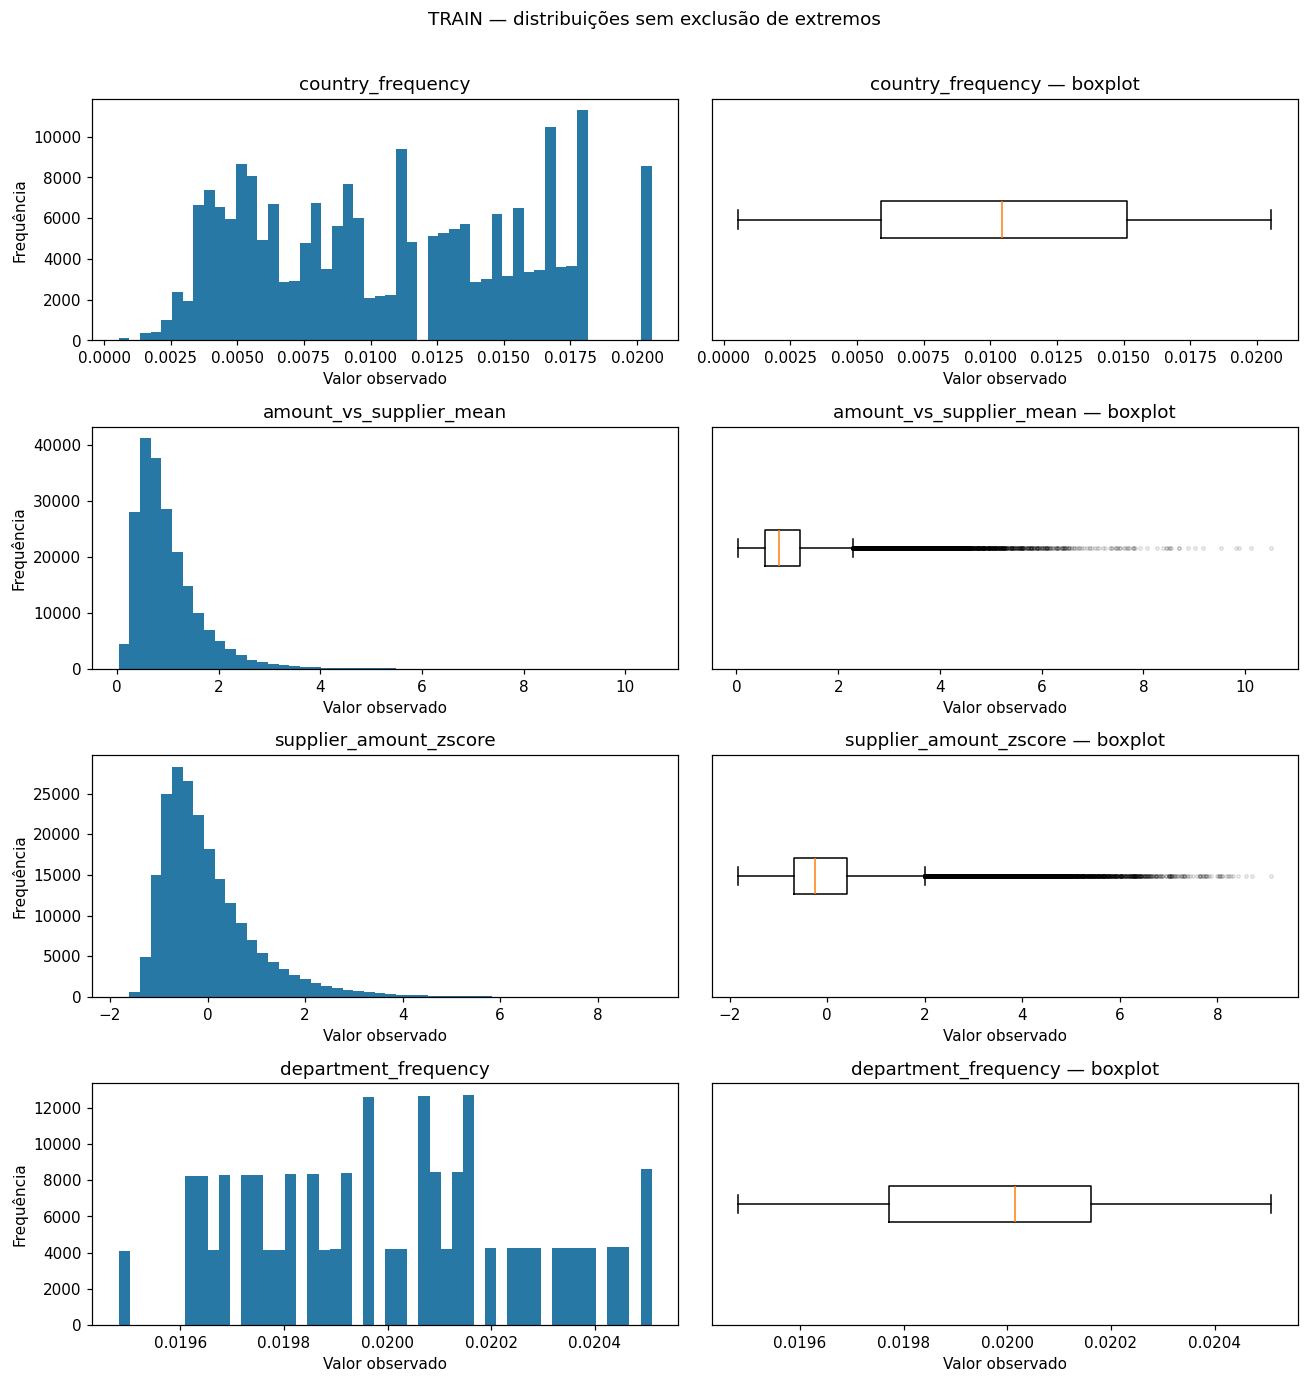

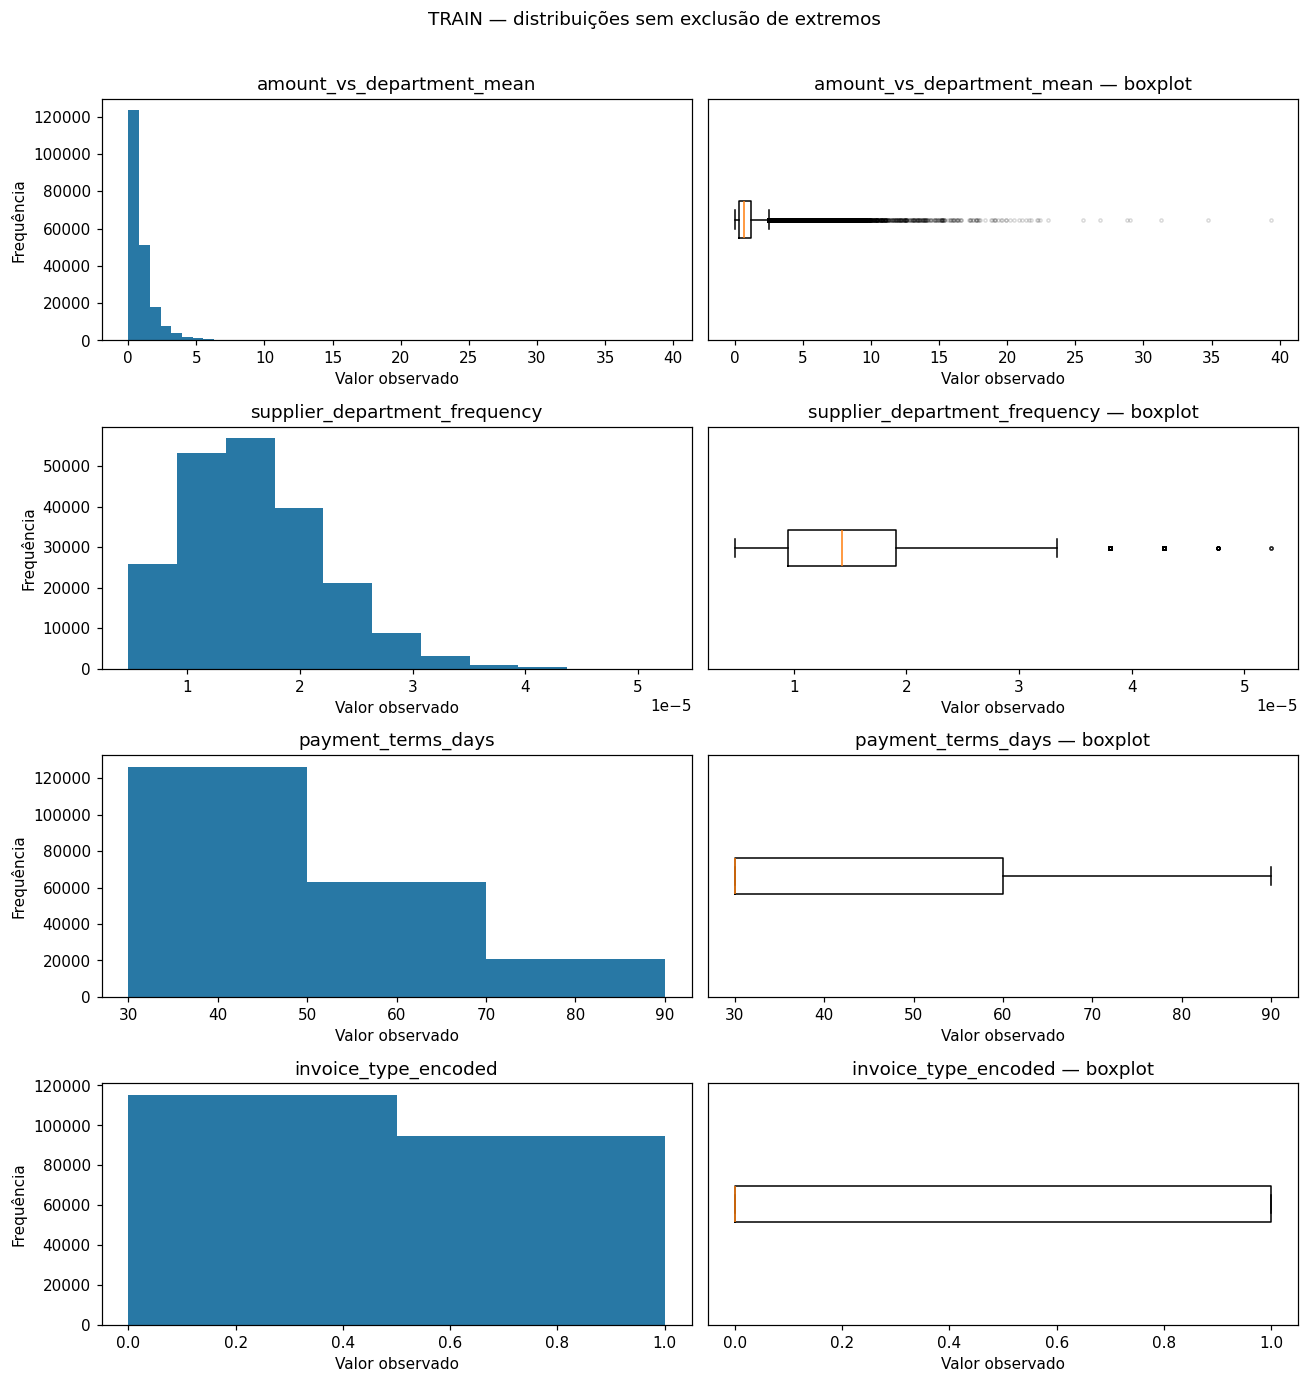

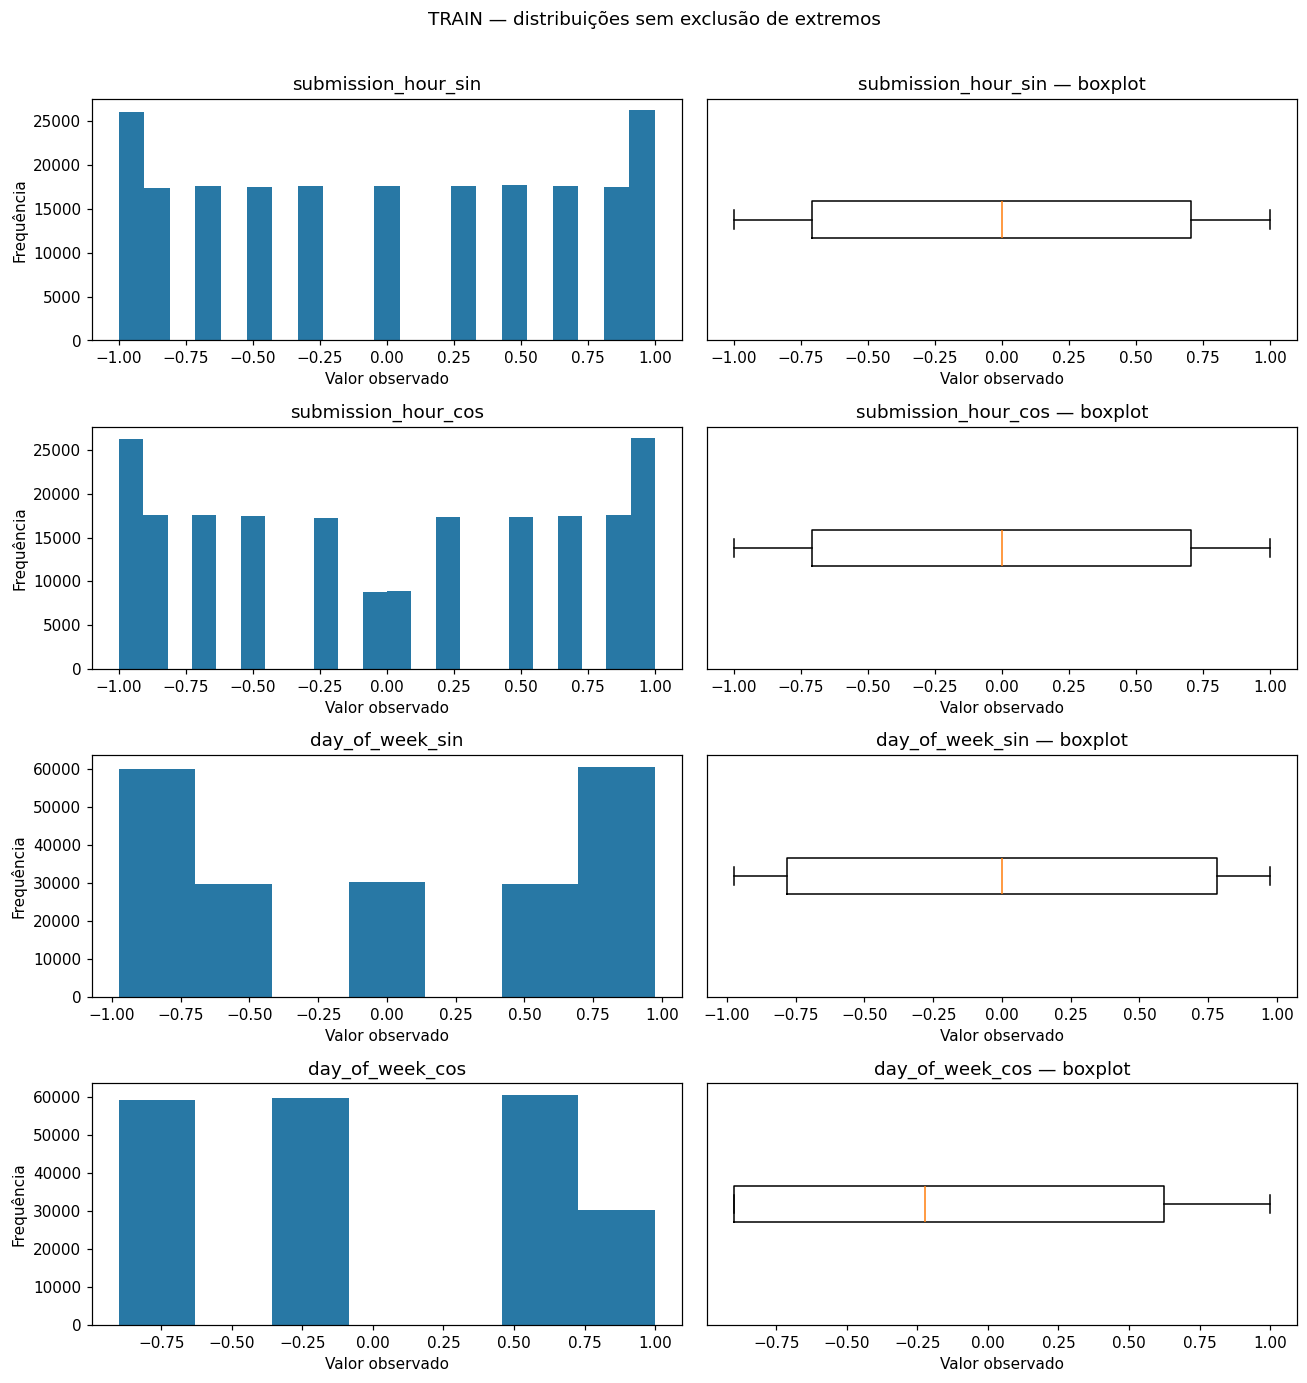

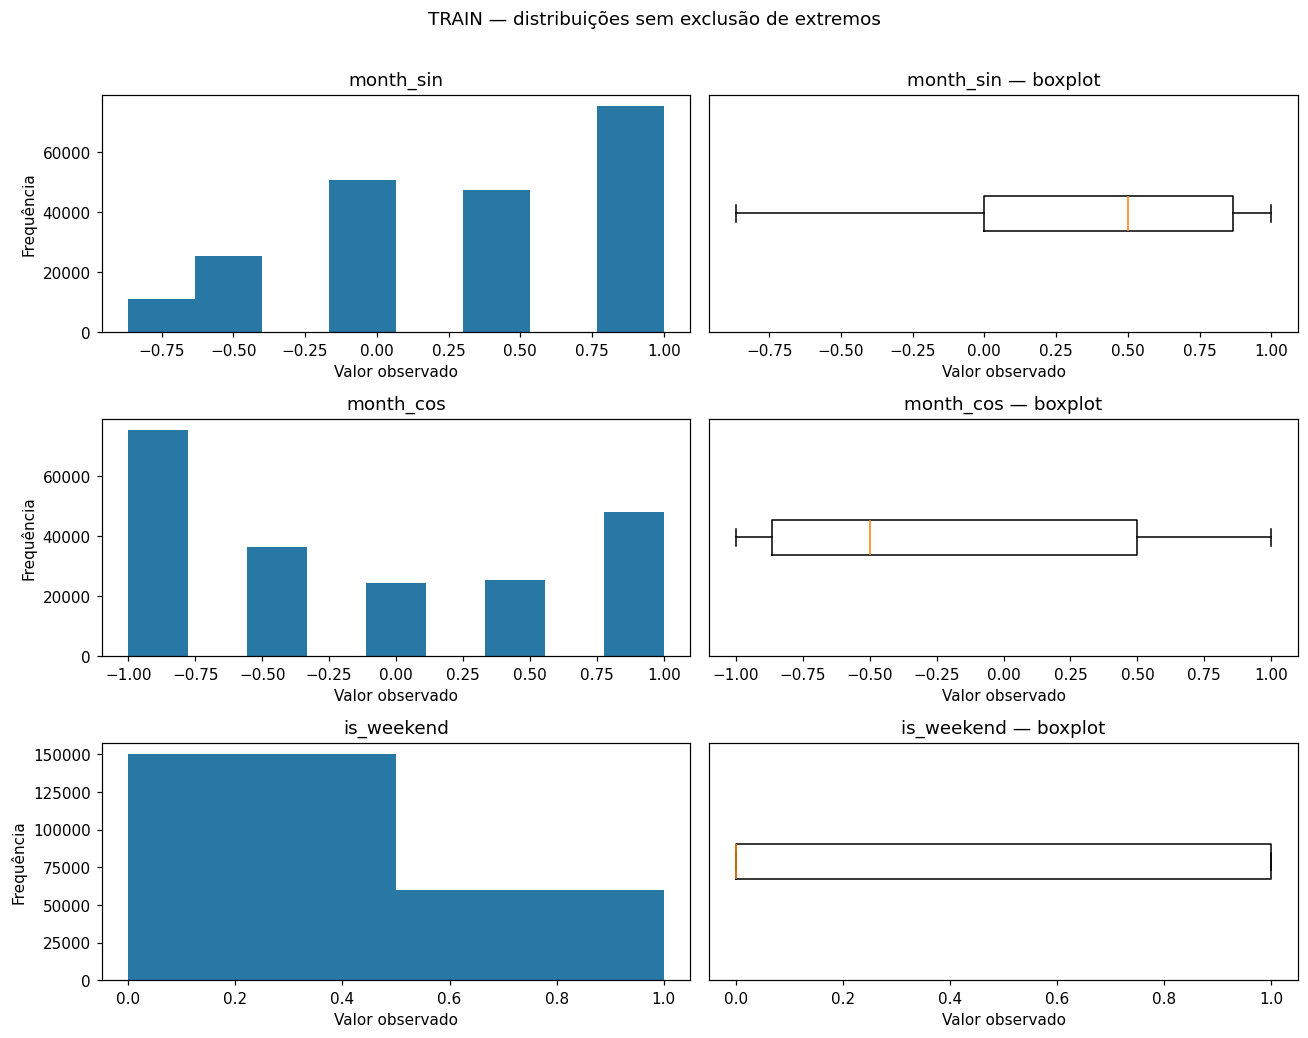

In [7]:
q1, q3 = features_train.quantile(0.25), features_train.quantile(0.75)
iqr = q3 - q1
quantidade_outliers = (
    (features_train.lt(q1 - 1.5 * iqr)) | (features_train.gt(q3 + 1.5 * iqr))
).sum()
resumo_outliers = pd.DataFrame(
    {
        "limite_inferior_IQR": q1 - 1.5 * iqr,
        "limite_superior_IQR": q3 + 1.5 * iqr,
        "fora_cercas_IQR": quantidade_outliers,
        "percentual": 100 * quantidade_outliers / len(features_train),
    }
)
display(resumo_outliers)
for start in range(0, len(FEATURES), 4):
    names = FEATURES[start : start + 4]
    fig, axes = plt.subplots(
        len(names), 2, figsize=(12, 3.1 * len(names)), squeeze=False
    )
    for row, name in enumerate(names):
        values = features_train[name].dropna()
        axes[row, 0].hist(
            values, bins=min(50, max(2, values.nunique())), color="#2878a5"
        )
        axes[row, 0].set(title=name, ylabel="Frequência", xlabel="Valor observado")
        axes[row, 1].boxplot(
            values,
            orientation="horizontal",
            flierprops={"markersize": 2, "alpha": 0.15},
        )
        axes[row, 1].set(title=f"{name} — boxplot", xlabel="Valor observado", yticks=[])
    fig.suptitle("TRAIN — distribuições sem exclusão de extremos", y=1.01)
    plt.tight_layout()
    plt.show()


## 5. Comparação descritiva entre as classes da referência

Todas as 19 features são comparadas por count, média, mediana e desvio padrão. Boxplots por classe complementam a tabela; contagens diferentes exigem cuidado. Diferenças não autorizam selecionar features, alterar o modelo ou inferir causalidade.


is_fraud                                              0            1
feature                       estatística                           
invoice_amount                count       163873.000000 46127.000000
                              mean          7425.190377  8067.283459
                              median        5450.350000  2928.060000
                              std           6221.111122 14635.777754
log_invoice_amount            count       163873.000000 46127.000000
                              mean             8.598887     8.158796
                              median           8.603619     7.982437
                              std              0.812423     1.184385
supplier_age_days             count       163873.000000 46127.000000
                              mean          2268.401457  2224.813537
                              median        2245.000000  2227.000000
                              std           1568.721594  1563.798091
supplier_frequency            count       163873.000000 46127.000000
                              mean             0.000505     0.000506
                              median           0.000505     0.000505
                              std              0.000049     0.000049
country_frequency             count       163873.000000 46127.000000
                              mean             0.010718     0.010622
                              median           0.010448     0.010448
                              std              0.005047     0.004992
amount_vs_supplier_mean       count       163873.000000 46127.000000
                              mean             1.076769     0.727265
                              median           0.916629     0.416728
                              std              0.596171     0.763288
supplier_amount_zscore        count       163873.000000 46127.000000
                              mean             0.119740    -0.425393
                              median          -0.127801    -0.870036
                              std              0.917006     1.135790
department_frequency          count       163873.000000 46127.000000
                              mean             0.020003     0.020005
                              median           0.020014     0.020014
                              std              0.000265     0.000265
amount_vs_department_mean     count       163873.000000 46127.000000
                              mean             0.981431     1.065970
                              median           0.720347     0.387294
                              std              0.822387     1.932331
supplier_department_frequency count       163873.000000 46127.000000
                              mean             0.000015     0.000015
                              median           0.000014     0.000014
                              std              0.000007     0.000007
payment_terms_days            count       163873.000000 46127.000000
                              mean            44.906360    44.956099
                              median          30.000000    30.000000
                              std             20.080934    20.049307
invoice_type_encoded          count       163873.000000 46127.000000
                              mean             0.451594     0.449802
                              median           0.000000     0.000000
                              std              0.497653     0.497479
submission_hour_sin           count       163873.000000 46127.000000
                              mean            -0.002717     0.021121
                              median           0.000000     0.000000
                              std              0.706659     0.704884
submission_hour_cos           count       163873.000000 46127.000000
                              mean            -0.004919     0.017297
                              median          -0.000000     0.000000
                              std              0.707536     0.70881

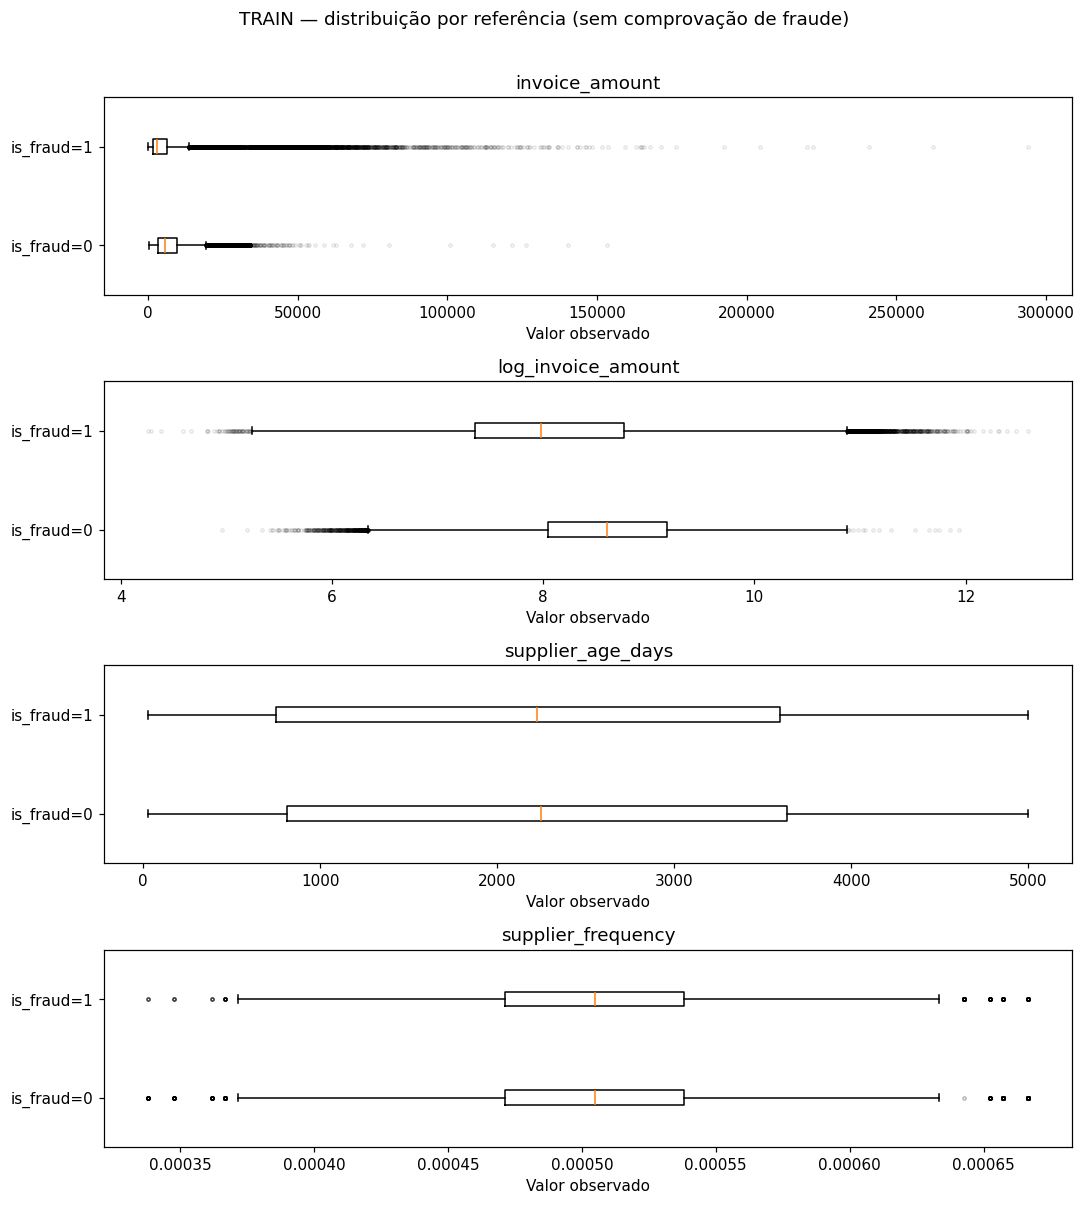

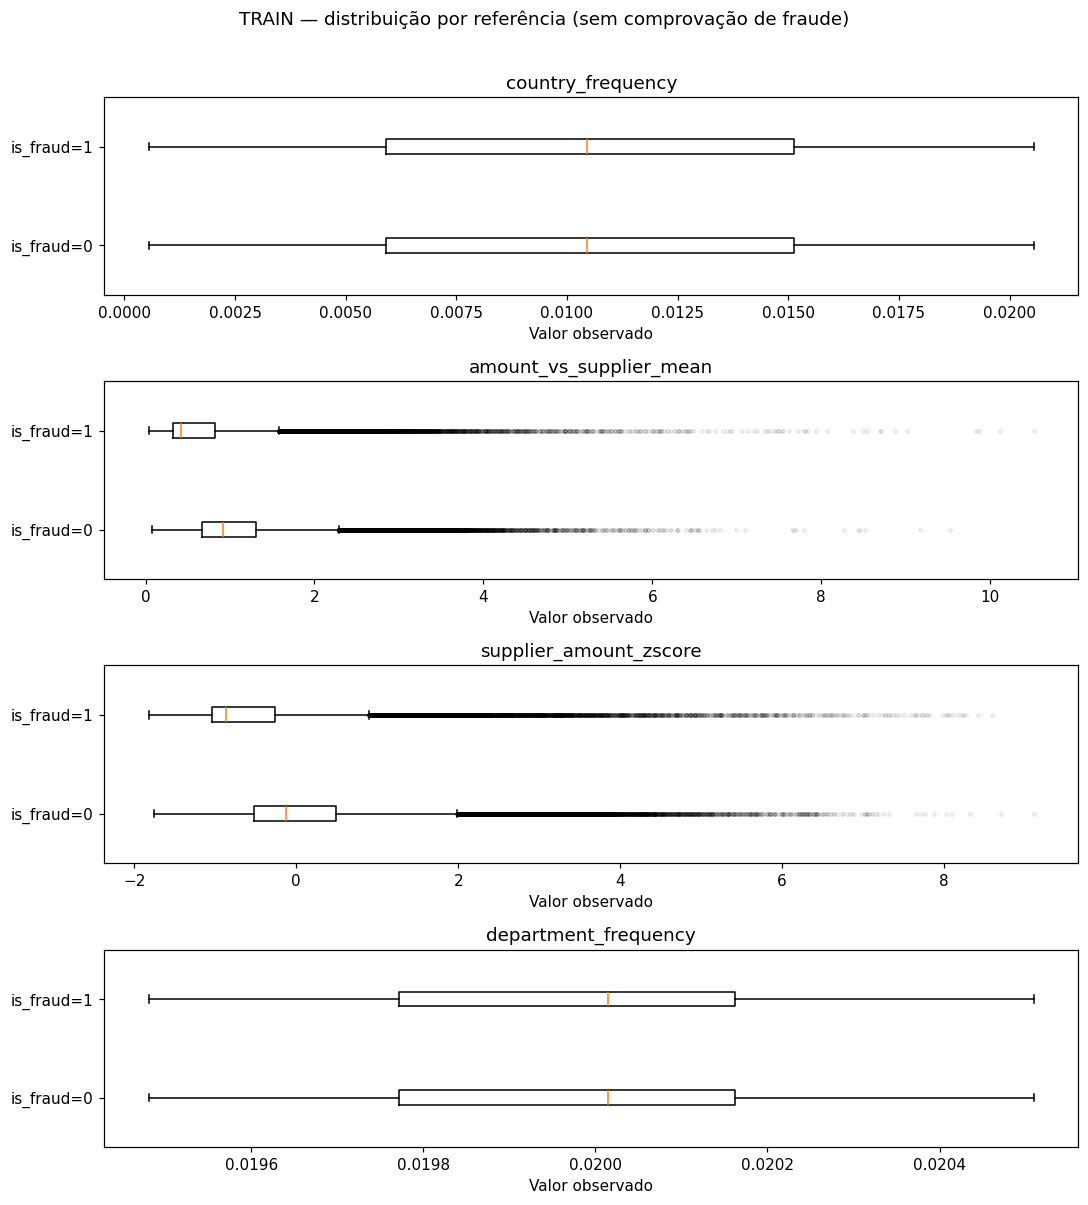

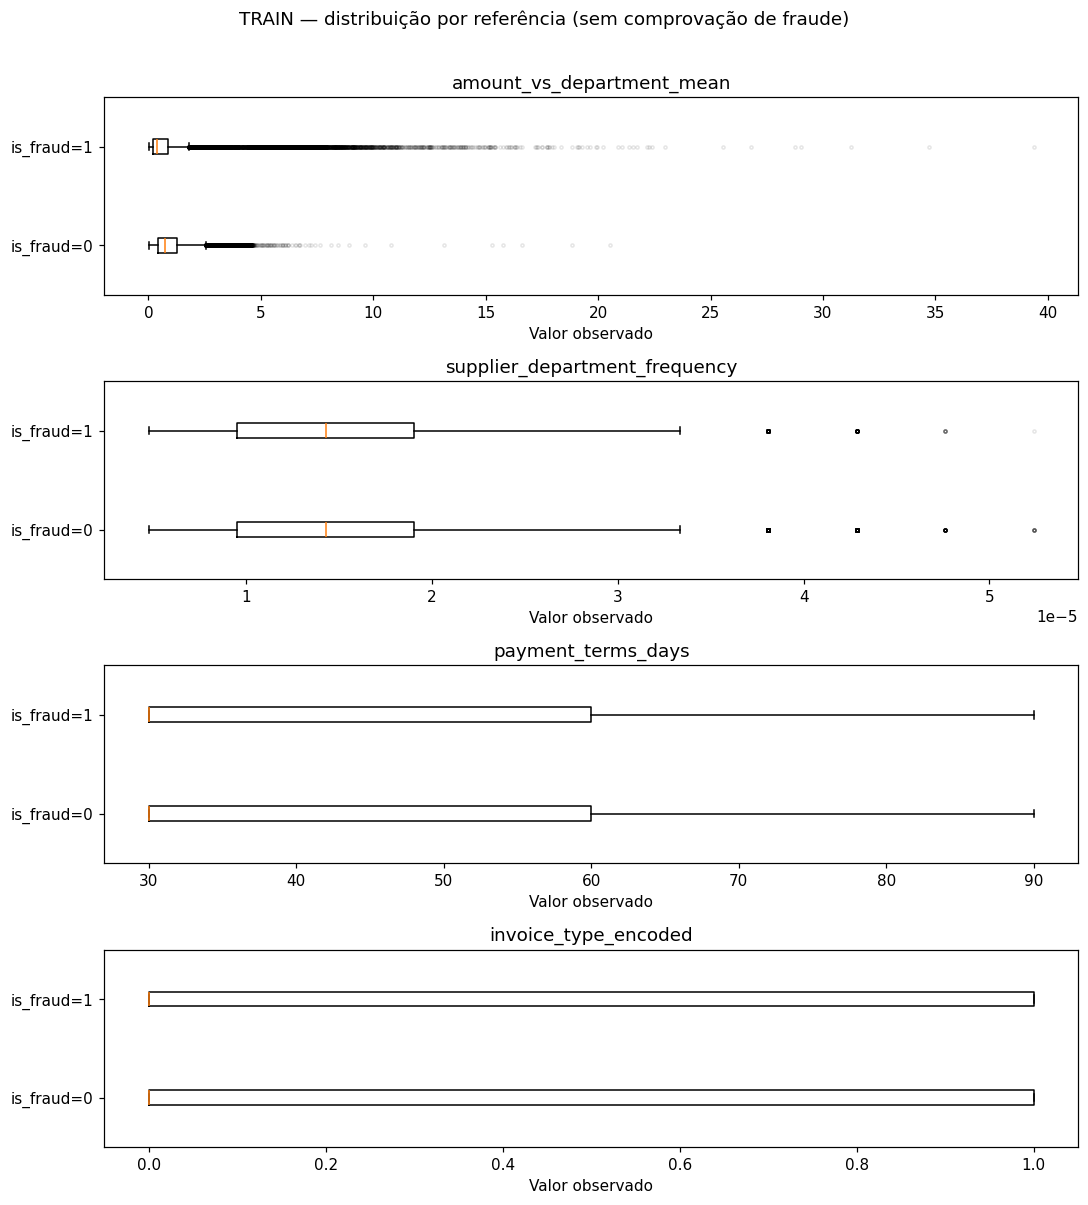

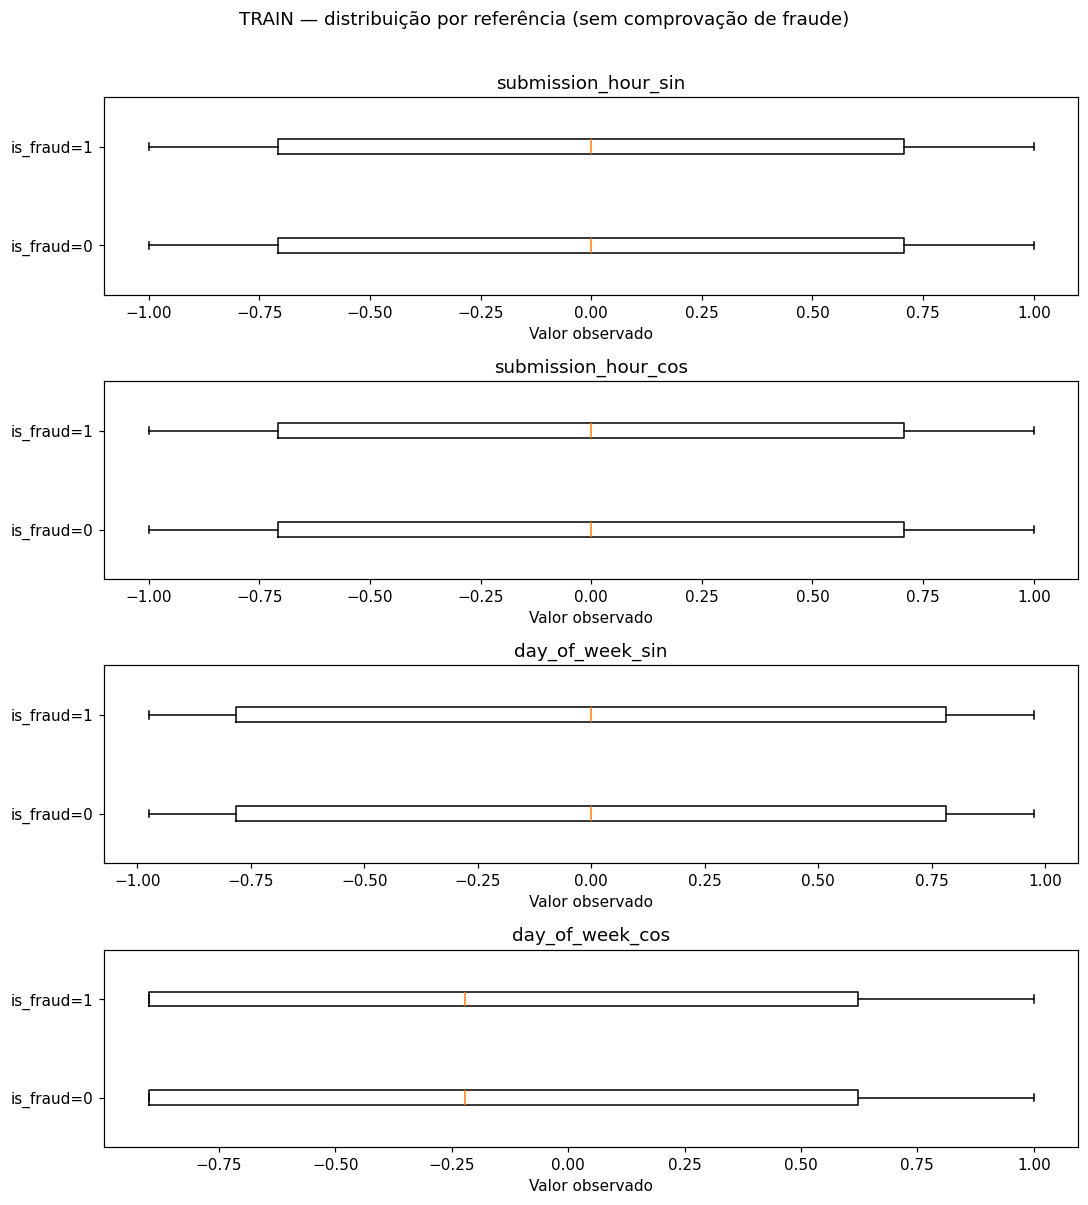

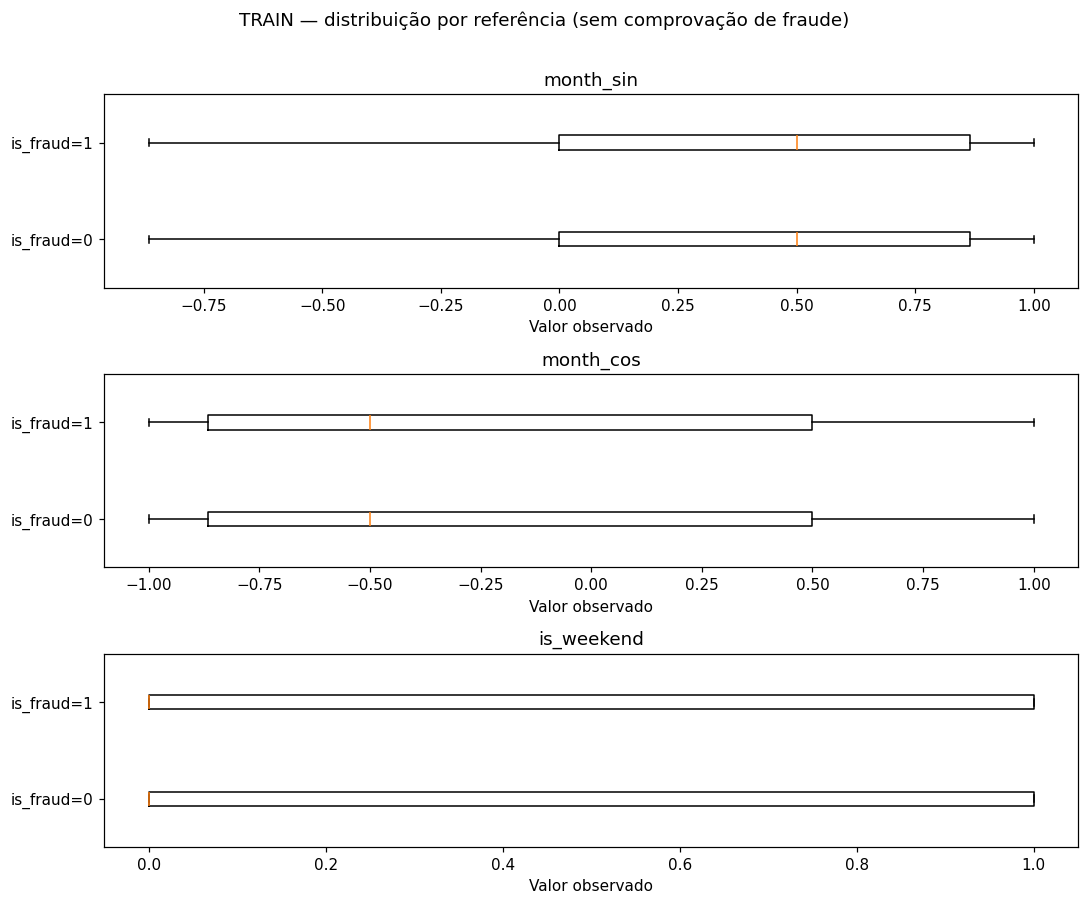

In [8]:
estatisticas_por_classe = compare_classes(features_train, referencia_fraude)
display(estatisticas_por_classe.T.rename_axis(index=["feature", "estatística"]))
for start in range(0, len(FEATURES), 4):
    names = FEATURES[start : start + 4]
    fig, axes = plt.subplots(
        len(names), 1, figsize=(10, 2.7 * len(names)), squeeze=False
    )
    for row, name in enumerate(names):
        ax = axes[row, 0]
        ax.boxplot(
            [
                features_train.loc[referencia_fraude.eq(label), name].dropna()
                for label in [0, 1]
            ],
            orientation="horizontal",
            tick_labels=["is_fraud=0", "is_fraud=1"],
            flierprops={"markersize": 2, "alpha": 0.1},
        )
        ax.set(title=name, xlabel="Valor observado")
    fig.suptitle(
        "TRAIN — distribuição por referência (sem comprovação de fraude)", y=1.01
    )
    plt.tight_layout()
    plt.show()


## 6. Correlação entre features

Pearson descreve associação linear; Spearman descreve associação monotônica por postos, inclusive com empates. Usam somente valores presentes de cada par. São **associações, não causalidade nem importância preditiva**. Componentes cíclicos, frequências e variáveis derivadas podem produzir associações pela própria representação. Correlação indefinida em constante deve permanecer NaN.

Os pares são apresentados uma única vez, sem diagonal. Nenhuma feature será removida mesmo quando a associação for alta.


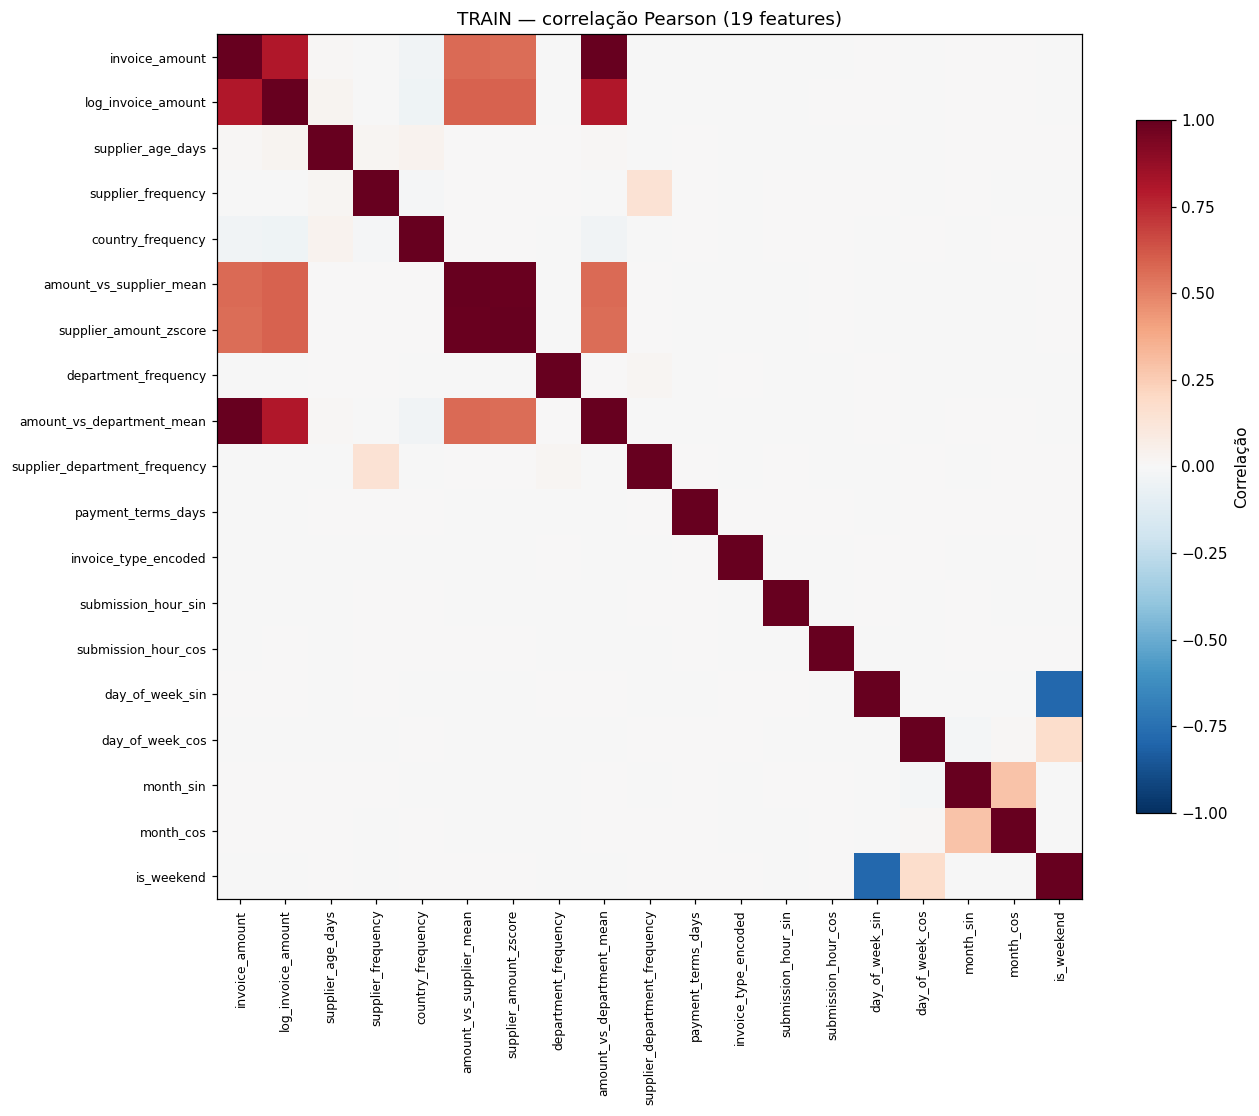

PEARSON — pares positivos mais fortes


,feature_a,feature_b,correlation
0,invoice_amount,amount_vs_department_mean,0.999804
1,amount_vs_supplier_mean,supplier_amount_zscore,0.991878
2,log_invoice_amount,amount_vs_department_mean,0.799126
3,invoice_amount,log_invoice_amount,0.798969
5,log_invoice_amount,supplier_amount_zscore,0.592080


PEARSON — pares negativos mais fortes


,feature_a,feature_b,correlation
4,day_of_week_sin,is_weekend,-0.786100
14,log_invoice_amount,country_frequency,-0.046712
15,country_frequency,amount_vs_department_mean,-0.037599
16,invoice_amount,country_frequency,-0.037568
20,day_of_week_cos,month_sin,-0.017417


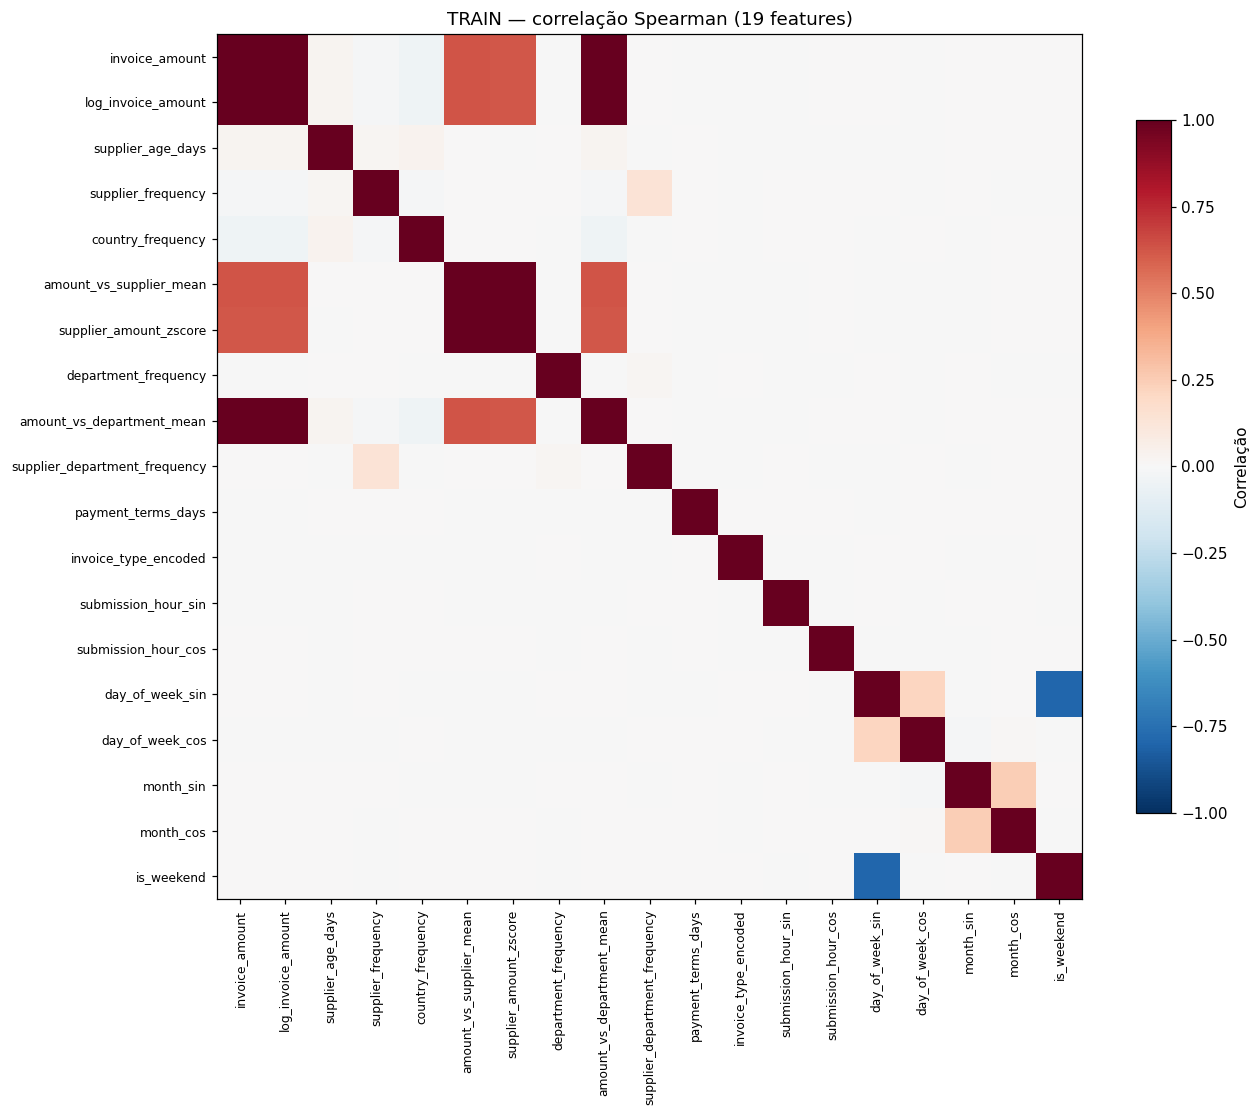

SPEARMAN — pares positivos mais fortes


,feature_a,feature_b,correlation
0,invoice_amount,log_invoice_amount,1.000000
1,invoice_amount,amount_vs_department_mean,0.999853
2,log_invoice_amount,amount_vs_department_mean,0.999853
3,amount_vs_supplier_mean,supplier_amount_zscore,0.993936
5,invoice_amount,amount_vs_supplier_mean,0.629170


SPEARMAN — pares negativos mais fortes


,feature_a,feature_b,correlation
4,day_of_week_sin,is_weekend,-0.790050
14,country_frequency,amount_vs_department_mean,-0.044142
15,invoice_amount,country_frequency,-0.044114
16,log_invoice_amount,country_frequency,-0.044114
23,day_of_week_cos,month_sin,-0.013209


In [9]:
matrizes_correlacao = {
    method: features_train.corr(method=method) for method in ["pearson", "spearman"]
}
for method, matriz_correlacao in matrizes_correlacao.items():
    fig, ax = plt.subplots(figsize=(12, 10))
    plot = ax.imshow(matriz_correlacao, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8)
    ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
    ax.set_title(f"TRAIN — correlação {method.title()} (19 features)")
    fig.colorbar(plot, ax=ax, shrink=0.8, label="Correlação")
    plt.tight_layout()
    plt.show()
    pairs = correlation_pairs(matriz_correlacao)
    print(method.upper(), "— pares positivos mais fortes")
    display(pairs[pairs.correlation.gt(0)].head(5))
    print(method.upper(), "— pares negativos mais fortes")
    display(pairs[pairs.correlation.lt(0)].head(5))


## 7. Associação com `is_fraud` — requisito acadêmico

Para uma variável binária 0/1, **Pearson equivale à correlação ponto-bisserial**. Spearman oferece a comparação por postos. O ranking abaixo ordena pelo valor absoluto de Pearson e mantém o sinal das duas medidas. Não é uma seleção de features nem um ranking de importância do modelo.

`invoice_type_encoded` já pertence às 19 features (GOODS=0, SERVICES=1 na engenharia existente). Sua correlação é apresentada, mas depende dessa codificação; não implica uma relação ordinal natural entre tipos. Não se codificam categorias nominais adicionais. Os componentes seno/cosseno dependem da fase; correlação univariada pequena não demonstra ausência de associação conjunta ou não linear.


,Pearson / ponto-bisserial,Spearman
supplier_amount_zscore,-0.226773,-0.381746
amount_vs_supplier_mean,-0.221630,-0.392119
log_invoice_amount,-0.196891,-0.218852
invoice_amount,0.030232,-0.218852
amount_vs_department_mean,0.030133,-0.218734
month_cos,-0.019146,-0.018539
submission_hour_sin,0.013972,0.012274
submission_hour_cos,0.012994,0.013729
supplier_age_days,-0.011511,-0.012496
supplier_frequency,0.011219,0.005823


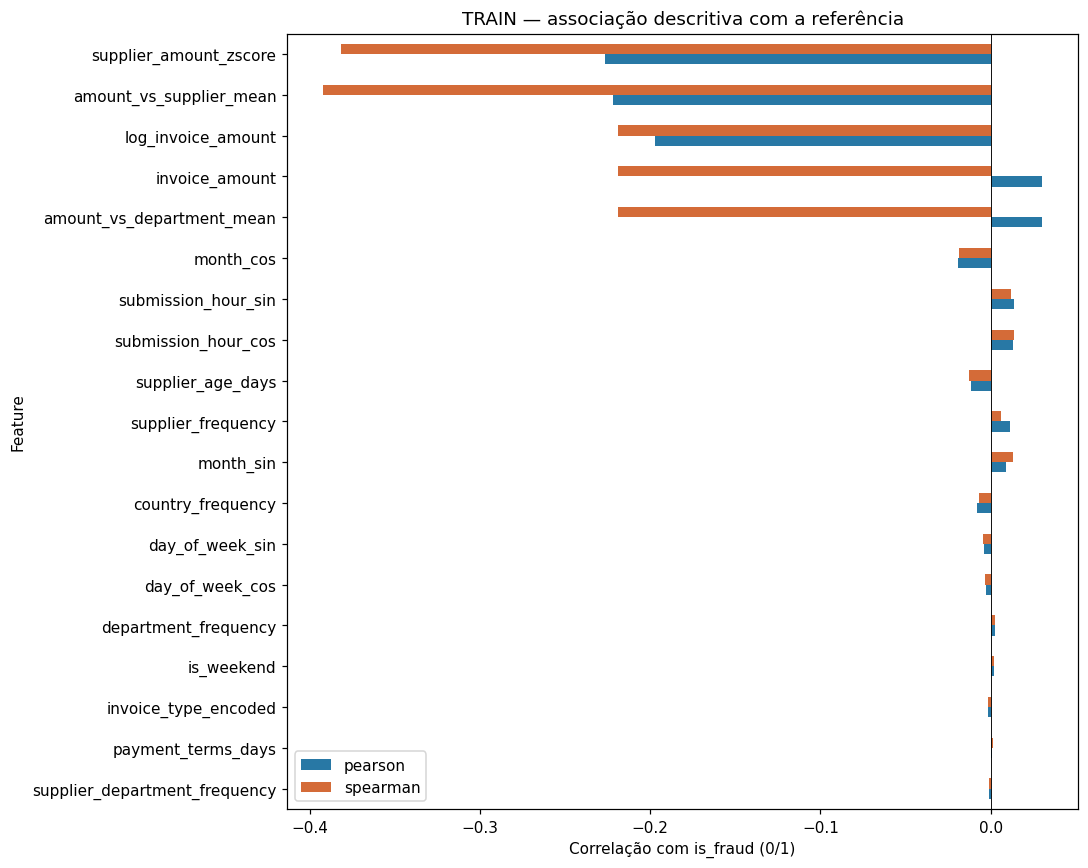

In [10]:
ranking_correlacoes = target_correlations(features_train, referencia_fraude)
display(
    ranking_correlacoes.rename(
        columns={"pearson": "Pearson / ponto-bisserial", "spearman": "Spearman"}
    )
)
fig, ax = plt.subplots(figsize=(10, 8))
ranking_correlacoes.iloc[::-1].plot.barh(ax=ax, color=["#2878a5", "#d46b38"])
ax.axvline(0, color="black", linewidth=0.6)
ax.set(
    xlabel="Correlação com is_fraud (0/1)",
    ylabel="Feature",
    title="TRAIN — associação descritiva com a referência",
)
plt.tight_layout()
plt.show()


## 8. Conclusões calculadas e limitações

### Leitura dos resultados observados

- As 210.000 faturas têm 23 colunas e nenhuma ausência, duplicata exata ou vetor de features repetido. A referência contém 78,0348% de classe 0 e 21,9652% de classe 1.
- Os histogramas mostram cauda direita pronunciada em invoice_amount e amount_vs_department_mean; as duas features relativas ao fornecedor também têm extremos superiores. log_invoice_amount já estava no arquivo e apresenta perfil mais simétrico. Não se aplicou novo log.
- supplier_age_days tem concentração visual no início de sua faixa; supplier_frequency está centrada perto de 0,000505. department_frequency ocupa faixa estreita; country_frequency é irregular e supplier_department_frequency é discreta. Esses números não permitem contar entidades originais.
- payment_terms_days, invoice_type_encoded e is_weekend têm poucos valores; seno/cosseno de hora, semana e mês mostram concentrações discretas próprias da representação, sem reconstrução de período.
- Há 15.382 valores de invoice_amount fora das cercas IQR (7,3248%). As marcações visuais não implicam erros, fraude ou alertas do modelo.
- Na classe 1, invoice_amount tem média maior (8.067,28 contra 7.425,19), mediana menor (2.928,06 contra 5.450,35) e maior dispersão. Pearson é +0,030232, enquanto Spearman é −0,218852: não há uma relação única resumida adequadamente pelo sinal de uma só medida.
- As maiores associações absolutas de Pearson com a referência são negativas: supplier_amount_zscore (−0,226773), amount_vs_supplier_mean (−0,221630) e log_invoice_amount (−0,196891). As demais são pequenas em Pearson; isso não exclui relações não lineares.
- invoice_amount e amount_vs_department_mean têm Pearson 0,999804; amount_vs_supplier_mean e supplier_amount_zscore têm 0,991878. invoice_amount e log_invoice_amount têm Spearman 1. Nenhuma feature foi excluída.
- O cruzamento das referências mostra 3.374 is_fraud=1 com fraud_type=NONE e 887 is_fraud=0 com outro tipo. São divergências descritivas preservadas, sem atribuir automaticamente qual campo estaria correto.
- A contagem de zeros usa igualdade exata; arredondamento de números trigonométricos muito próximos de zero não altera a contagem.

Os resumos seguintes são gerados a partir das tabelas acima. “Próxima de zero” significa apenas |Pearson| < 0,05 para apresentação descritiva, não teste de significância, independência ou critério de seleção. “Alta correlação” usa |r| ≥ 0,8 somente como destaque visual.

As labels não têm validade empresarial comprovada e podem discordar de `fraud_type`. Não foram corrigidas. O TRAIN usado para gerar agregações contém contribuições das próprias faturas e não oferece garantia ponto-no-tempo. Registros podem compartilhar fornecedores, mas os IDs originais estão ausentes; não se assume independência estatística nem se calculam p-valores.

`source_reconciled=false` permanece: verificar o arquivo processado não certifica a procedência independente do treinamento legado. Esta EDA não demonstra qualidade operacional, detecção de fraude real ou generalização. Nenhuma conclusão altera modelo, features, threshold ou decisões previamente documentadas.


In [11]:
correlacoes_positivas = (
    ranking_correlacoes[ranking_correlacoes.pearson.gt(0)]
    .sort_values("pearson", ascending=False)
    .head(3)
)
correlacoes_negativas = (
    ranking_correlacoes[ranking_correlacoes.pearson.lt(0)]
    .sort_values("pearson")
    .head(3)
)
correlacoes_proximas_zero = ranking_correlacoes.index[
    ranking_correlacoes.pearson.abs().lt(0.05)
].tolist()
print(
    f"TRAIN: {len(dados_train):,} faturas; {len(FEATURES)} features; {dados_train.shape[1]} colunas."
)
print("Distribuição da referência:")
display(distribuicao_classes)
print("Maiores associações positivas (Pearson):")
display(correlacoes_positivas)
print("Maiores associações negativas (Pearson):")
display(correlacoes_negativas)
print("Associação linear próxima de zero (|r| < 0,05):", correlacoes_proximas_zero)
print("Maiores assimetrias positivas observadas:")
display(
    resumo_distribuicoes.sort_values("assimetria_amostral", ascending=False).head(5)
)
print("Maiores contagens fora das cercas IQR — não equivalem a erros:")
display(resumo_outliers.sort_values("fora_cercas_IQR", ascending=False).head(5))
for method, matriz_correlacao in matrizes_correlacao.items():
    pairs = correlation_pairs(matriz_correlacao)
    print(f"Pares com |{method}| >= 0,8:")
    display(pairs[pairs.correlation.abs().ge(0.8)])
display(
    Markdown(
        "**Conclusão de escopo:** análise descritiva concluída apenas sobre TRAIN. "
        "Fornecedores, departamentos, países e período não foram reconstruídos. "
        "Nenhuma decisão de modelagem foi tomada; is_fraud permaneceu referência."
    )
)


TRAIN: 210,000 faturas; 19 features; 23 colunas.
Distribuição da referência:


,quantidade,percentual
is_fraud,,
0,163873,78.034762
1,46127,21.965238


Maiores associações positivas (Pearson):


,pearson,spearman
invoice_amount,0.030232,-0.218852
amount_vs_department_mean,0.030133,-0.218734
submission_hour_sin,0.013972,0.012274


Maiores associações negativas (Pearson):


...

Pares com |pearson| >= 0,8:


,feature_a,feature_b,correlation
0,invoice_amount,amount_vs_department_mean,0.999804
1,amount_vs_supplier_mean,supplier_amount_zscore,0.991878


Pares com |spearman| >= 0,8:


,feature_a,feature_b,correlation
0,invoice_amount,log_invoice_amount,1.000000
1,invoice_amount,amount_vs_department_mean,0.999853
2,log_invoice_amount,amount_vs_department_mean,0.999853
3,amount_vs_supplier_mean,supplier_amount_zscore,0.993936


**Conclusão de escopo:** análise descritiva concluída apenas sobre TRAIN. Fornecedores, departamentos, países e período não foram reconstruídos. Nenhuma decisão de modelagem foi tomada; is_fraud permaneceu referência.

## 9. Conferência final de integridade

Somente o mesmo TRAIN é hasheado novamente. Não há varredura de diretórios de dados nem hash de VALIDATION/TEST. Não se escreve nenhum Parquet. A lista de features vem da implementação atual e não foi modificada.


In [12]:
assert features_train.columns.tolist() == FEATURES
assert (
    "is_fraud" not in features_train.columns
    and "invoice_id" not in features_train.columns
)
assert dados_train["split"].eq("train").all()
assert (
    hashlib.sha256(
        (PROJECT_ROOT / "data/processed/train_features.parquet").read_bytes()
    ).hexdigest()
    == train_sha256
), "O TRAIN foi alterado durante a análise."
print(
    "TRAIN íntegro; 19 features preservadas; nenhum treinamento ou avaliação executado."
)


TRAIN íntegro; 19 features preservadas; nenhum treinamento ou avaliação executado.
